# NS EQUATIONS (CAVITY FLOW SOLUTION)

In this module we will cover multiple solutions of NS equations based on diferent boundary conditions.

General Case:
we write both momentum conservation solutions:

$$\frac{\partial u}{\partial t}+u\frac{\partial u}{\partial x}+v\frac{\partial u}{\partial y} = -\frac{1}{\rho}\frac{\partial p}{\partial x}+\nu \left(\frac{\partial^2 u}{\partial x^2}+\frac{\partial^2 u}{\partial y^2} \right) $$


$$\frac{\partial v}{\partial t}+u\frac{\partial v}{\partial x}+v\frac{\partial v}{\partial y} = -\frac{1}{\rho}\frac{\partial p}{\partial y}+\nu\left(\frac{\partial^2 v}{\partial x^2}+\frac{\partial^2 v}{\partial y^2}\right) $$

Then we have to analyse the divergent of the momentum conservation to get a poisson equation in pressure:

$$\frac{\partial^2 p}{\partial x^2}+\frac{\partial^2 p}{\partial y^2} = \rho\left(\frac{\partial}{\partial t}\left(\frac{\partial u}{\partial x} +\frac{\partial v}{\partial y} \right) - \frac{\partial u}{\partial x}\frac{\partial u}{\partial x}-2\frac{\partial u}{\partial y}\frac{\partial v}{\partial x}-\frac{\partial v}{\partial y}\frac{\partial v}{\partial y} \right)$$

We discretize these equations to solve for $u^{n+1}_{i, j}$ and $v^{n+1}_{i, j}$ for each time iteration and solve for $p^{n}_{i, j}$ in a internal loop. Where:

The momentum equation in the $u$ direction:

$$
\begin{split}
u_{i,j}^{n+1} = u_{i,j}^{n} & - u_{i,j}^{n} \frac{\Delta t}{\Delta x} \left(u_{i,j}^{n}-u_{i-1,j}^{n}\right) - v_{i,j}^{n} \frac{\Delta t}{\Delta y} \left(u_{i,j}^{n}-u_{i,j-1}^{n}\right) \\
& - \frac{\Delta t}{\rho 2\Delta x} \left(p_{i+1,j}^{n}-p_{i-1,j}^{n}\right) \\
& + \nu \left(\frac{\Delta t}{\Delta x^2} \left(u_{i+1,j}^{n}-2u_{i,j}^{n}+u_{i-1,j}^{n}\right) + \frac{\Delta t}{\Delta y^2} \left(u_{i,j+1}^{n}-2u_{i,j}^{n}+u_{i,j-1}^{n}\right)\right)
\end{split}
$$

The momentum equation in the $v$ direction:

$$
\begin{split}
v_{i,j}^{n+1} = v_{i,j}^{n} & - u_{i,j}^{n} \frac{\Delta t}{\Delta x} \left(v_{i,j}^{n}-v_{i-1,j}^{n}\right) - v_{i,j}^{n} \frac{\Delta t}{\Delta y} \left(v_{i,j}^{n}-v_{i,j-1}^{n})\right) \\
& - \frac{\Delta t}{\rho 2\Delta y} \left(p_{i,j+1}^{n}-p_{i,j-1}^{n}\right) \\
& + \nu \left(\frac{\Delta t}{\Delta x^2} \left(v_{i+1,j}^{n}-2v_{i,j}^{n}+v_{i-1,j}^{n}\right) + \frac{\Delta t}{\Delta y^2} \left(v_{i,j+1}^{n}-2v_{i,j}^{n}+v_{i,j-1}^{n}\right)\right)
\end{split}
$$

And for the Poisson pressure equation

$$
\begin{split}
p_{i,j}^{n} = & \frac{\left(p_{i+1,j}^{n}+p_{i-1,j}^{n}\right) \Delta y^2 + \left(p_{i,j+1}^{n}+p_{i,j-1}^{n}\right) \Delta x^2}{2\left(\Delta x^2+\Delta y^2\right)} \\
& -\frac{\rho\Delta x^2\Delta y^2}{2\left(\Delta x^2+\Delta y^2\right)} \\
& \times \left[\frac{1}{\Delta t}\left(\frac{u_{i+1,j}-u_{i-1,j}}{2\Delta x}+\frac{v_{i,j+1}-v_{i,j-1}}{2\Delta y}\right)-\frac{u_{i+1,j}-u_{i-1,j}}{2\Delta x}\frac{u_{i+1,j}-u_{i-1,j}}{2\Delta x} -2\frac{u_{i,j+1}-u_{i,j-1}}{2\Delta y}\frac{v_{i+1,j}-v_{i-1,j}}{2\Delta x}-\frac{v_{i,j+1}-v_{i,j-1}}{2\Delta y}\frac{v_{i,j+1}-v_{i,j-1}}{2\Delta y}\right]
\end{split}
$$

The initial condition is $u, v, p = 0$ everywhere, and the boundary conditions are:

$u=1$ at $y=2$ (the "lid");

$u, v=0$ on the other boundaries;

$\frac{\partial p}{\partial y}=0$ at $y=0$;

$p=0$ at $y=2$

$\frac{\partial p}{\partial x}=0$ at $x=0,2$

In [28]:
import numpy as np
from matplotlib import pyplot as plt, cm

In [29]:
#Space Discretization
nx = 41
ny = 41
dx = 2 / (nx - 1)
dy = 2 / (ny - 1)
x = np.linspace(0, 2, nx)
y = np.linspace(0, 2, ny)
X, Y = np.meshgrid(x, y)

#Physical Parameters
rho = 1
nu = 0.01

#time
dt = 0.001
nt = 100


#Solution Parameters
nits = 500
crit = 1e-4
c = 1
small = 1e-8

In [30]:
#initialize vectors with initial conditions
u = np.zeros((ny, nx))
v = np.zeros((ny, nx))
p = np.zeros((ny, nx))
b = np.zeros((ny, nx))


In [31]:
#Function to compute the source term b of the pressure poissons equation
def build_up_b(b, rho, dt, u, v, dx, dy):
        
    b[1:-1, 1:-1] = (rho * 
                (1 / dt * ((u[1:-1, 2:] - u[1:-1, 0:-2]) / (2 * dx) + (v[2:, 1:-1] - v[0:-2, 1:-1]) / (2 * dy)) -
                ((u[1:-1, 2:] - u[1:-1, 0:-2]) / (2 * dx)*(u[1:-1, 2:] - u[1:-1, 0:-2]) / (2 * dx)) -
                2 * ((u[2:, 1:-1] - u[0:-2, 1:-1]) / (2 * dy) *(v[1:-1, 2:] - v[1:-1, 0:-2]) / (2 * dx))-
                ((v[2:, 1:-1] - v[0:-2, 1:-1]) / (2 * dy)*(v[2:, 1:-1] - v[0:-2, 1:-1]) / (2 * dy))))
 
    return b

In [32]:
def pressure_poisson(p, dx, dy, b):
    pn = np.empty_like(p)
    pn = p.copy()
    
    for q in range(nits):
        pn = p.copy()
        p[1:-1, 1:-1] = (((pn[1:-1, 2:] + pn[1:-1, 0:-2]) * dy**2 + 
                          (pn[2:, 1:-1] + pn[0:-2, 1:-1]) * dx**2) /
                          (2 * (dx**2 + dy**2)) -
                          dx**2 * dy**2 / (2 * (dx**2 + dy**2)) * 
                          b[1:-1,1:-1])

        #Boundary conditions
        p[:, -1] = p[:, -2]   # dp/dx = 0 at x = 2
        p[0, :] = p[1, :]     # dp/dy = 0 at y = 0
        p[:, 0] = p[:, 1]     # dp/dx = 0 at x = 0
        p[-1, :] = 0          # p = 0 at y = 2
        
    return p

In [33]:
def pressure_poisson_err(p, dx, dy, b, crit= 1e-4):
    pn = np.empty_like(p)
    pn = p.copy()

    err = 1
    iter_count = 0
    
    while err > crit:
        iter_count += 1
        pn = p.copy()
        p[1:-1, 1:-1] = (((pn[1:-1, 2:] + pn[1:-1, 0:-2]) * dy**2 + 
                          (pn[2:, 1:-1] + pn[0:-2, 1:-1]) * dx**2) /
                          (2 * (dx**2 + dy**2)) -
                          dx**2 * dy**2 / (2 * (dx**2 + dy**2)) * 
                          b[1:-1,1:-1])

        #Boundary conditions
        p[:, -1] = p[:, -2]   # dp/dx = 0 at x = 2
        p[0, :] = p[1, :]     # dp/dy = 0 at y = 0
        p[:, 0] = p[:, 1]     # dp/dx = 0 at x = 0
        p[-1, :] = 0          # p = 0 at y = 2
        
        #Error calculation
        err = (np.sum(abs(pn - p)) / (np.sum(abs(pn)) + small))

    return p

In [34]:
def velocity_u_update(u, dx, dy, dt, rho, p, un, vn):
    
    u[1:-1, 1:-1] = (un[1:-1, 1:-1]-
                    un[1:-1, 1:-1] * dt / dx *
                    (un[1:-1, 1:-1] - un[1:-1, 0:-2]) -
                    vn[1:-1, 1:-1] * dt / dy *
                    (un[1:-1, 1:-1] - un[0:-2, 1:-1]) -
                    dt / (2 * rho * dx) * (p[1:-1, 2:] - p[1:-1, 0:-2]) +
                    nu * (dt / dx**2 *
                    (un[1:-1, 2:] - 2 * un[1:-1, 1:-1] + un[1:-1, 0:-2]) +
                    dt / dy**2 *
                    (un[2:, 1:-1] - 2 * un[1:-1, 1:-1] + un[0:-2, 1:-1])))
    return u

def velocity_v_update(v, dx, dy, dt, rho, p, un, vn):
    
    v[1:-1,1:-1] = (vn[1:-1, 1:-1] -
                    un[1:-1, 1:-1] * dt / dx *
                    (vn[1:-1, 1:-1] - vn[1:-1, 0:-2]) -
                    vn[1:-1, 1:-1] * dt / dy *
                    (vn[1:-1, 1:-1] - vn[0:-2, 1:-1]) -
                    dt / (2 * rho * dy) * (p[2:, 1:-1] - p[0:-2, 1:-1]) +
                    nu * (dt / dx**2 *
                    (vn[1:-1, 2:] - 2 * vn[1:-1, 1:-1] + vn[1:-1, 0:-2]) +
                    dt / dy**2 *
                    (vn[2:, 1:-1] - 2 * vn[1:-1, 1:-1] + vn[0:-2, 1:-1])))
    return v


In [35]:
def cavity_flow_sol(nt, u, v, dt, dx, dy, p, rho, nu):
    un = np.empty_like(u)
    vn = np.empty_like(v)
    pn = np.empty_like(p)
    b = np.zeros((ny, nx))

    solution:list = []
    errors:list = []
    
    for n in range(nt):
        un = u.copy()
        vn = v.copy()
        pn = p.copy()
        b = build_up_b(b, rho, dt, un, vn, dx, dy) #update b value before iteration
        
        # calculate pressure field using Poisson equation
        #p = pressure_poisson(p, dx, dy, b)
        p = pressure_poisson_err(p, dx, dy, b, crit=crit)
        
        u = velocity_u_update(u, dx, dy, dt, rho, p, un, vn)
        v = velocity_v_update(v, dx, dy, dt, rho, p, un, vn)
        
        #Boundary conditions for velocity
        u[0, :]  = 0
        u[:, 0]  = 0
        u[:, -1] = 0
        u[-1, :] = c    # set velocity on cavity lid equal to c
        v[0, :]  = 0
        v[-1, :] = 0
        v[:, 0]  = 0
        v[:, -1] = 0
        
        solution.append([u.copy(), v.copy(), p.copy()])

        error_u = (np.sum(abs(un - u)) / (np.sum(abs(un)) + small))
        error_v = (np.sum(abs(vn - v)) / (np.sum(abs(vn)) + small))
        error_p = (np.sum(abs(pn - p)) / (np.sum(abs(pn)) + small))
        print(f'Iteration: {n}, error_u: {error_u:.6f}, error_v: {error_v:.6f}, error_p: {error_p:.6f}')
        errors.append([error_u, error_v, error_p])

        
    return solution, errors

In [36]:
#get solution
solutions, errors = cavity_flow_sol(nt, u, v, dt, dx, dy, p, rho, nu)

Iteration: 0, error_u: 4100000000.000000, error_v: 0.000000, error_p: 0.000000
Iteration: 1, error_u: 0.003805, error_v: 0.000000, error_p: 0.000000
Iteration: 2, error_u: 0.003876, error_v: 709094.899362, error_p: 310543476.940635
Iteration: 3, error_u: 0.003905, error_v: 1.599453, error_p: 0.748344
Iteration: 4, error_u: 0.003918, error_v: 0.788082, error_p: 0.345622
Iteration: 5, error_u: 0.003922, error_v: 0.520500, error_p: 0.219289
Iteration: 6, error_u: 0.003920, error_v: 0.385817, error_p: 0.158794
Iteration: 7, error_u: 0.003915, error_v: 0.305958, error_p: 0.123307
Iteration: 8, error_u: 0.003908, error_v: 0.252950, error_p: 0.100358
Iteration: 9, error_u: 0.003899, error_v: 0.215439, error_p: 0.084478
Iteration: 10, error_u: 0.003889, error_v: 0.187879, error_p: 0.072445
Iteration: 11, error_u: 0.003879, error_v: 0.166487, error_p: 0.063526
Iteration: 12, error_u: 0.003868, error_v: 0.149357, error_p: 0.056172
Iteration: 13, error_u: 0.003857, error_v: 0.135343, error_p: 0.0

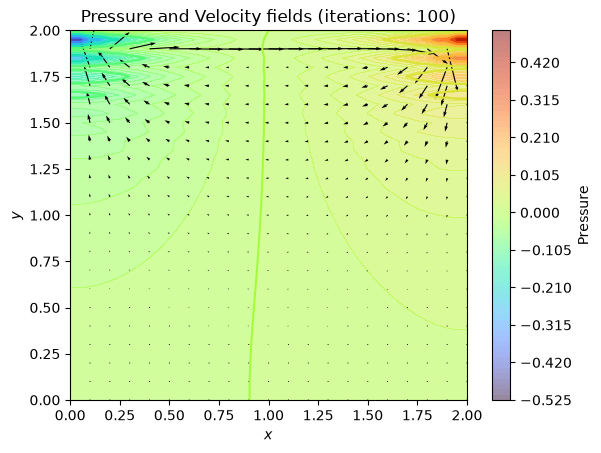

In [51]:
fig, ax = plt.subplots()

#pressure contour plot
contourf = ax.contourf(x, y, solutions[-1][2], levels= 100, cmap=cm.turbo, alpha=0.5)
colorbar = fig.colorbar(contourf, label='Pressure')

#pressure contours plot
contour = ax.contour(x, y, solutions[-1][2], levels= 10, cmap=cm.turbo, linewidths=1.5)
#plt.clabel(contour, inline=False, fontsize=12, colors = 'black')

# Quiver plot for velocity field
quiv = ax.quiver(X[::2, ::2], Y[::2, ::2], solutions[-1][0][::2, ::2], solutions[-1][1][::2, ::2], scale = .5)

#labels
ax.set_title(f'Pressure and Velocity fields (iterations: {nt})')
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')

plt.show()



In [57]:
#now solve 10000 iterations
nt = 10000
u = np.zeros((ny, nx))
v = np.zeros((ny, nx))
p = np.zeros((ny, nx))
b = np.zeros((ny, nx))

solution, errors = cavity_flow_sol(nt, u, v, dt, dx, dy, p, rho, nu)

Iteration: 0, error_u: 4100000000.000000, error_v: 0.000000, error_p: 0.000000
Iteration: 1, error_u: 0.003805, error_v: 0.000000, error_p: 0.000000
Iteration: 2, error_u: 0.003876, error_v: 709094.899362, error_p: 310543476.940635
Iteration: 3, error_u: 0.003905, error_v: 1.599453, error_p: 0.748344
Iteration: 4, error_u: 0.003918, error_v: 0.788082, error_p: 0.345622
Iteration: 5, error_u: 0.003922, error_v: 0.520500, error_p: 0.219289
Iteration: 6, error_u: 0.003920, error_v: 0.385817, error_p: 0.158794
Iteration: 7, error_u: 0.003915, error_v: 0.305958, error_p: 0.123307
Iteration: 8, error_u: 0.003908, error_v: 0.252950, error_p: 0.100358
Iteration: 9, error_u: 0.003899, error_v: 0.215439, error_p: 0.084478
Iteration: 10, error_u: 0.003889, error_v: 0.187879, error_p: 0.072445
Iteration: 11, error_u: 0.003879, error_v: 0.166487, error_p: 0.063526
Iteration: 12, error_u: 0.003868, error_v: 0.149357, error_p: 0.056172
Iteration: 13, error_u: 0.003857, error_v: 0.135343, error_p: 0.0

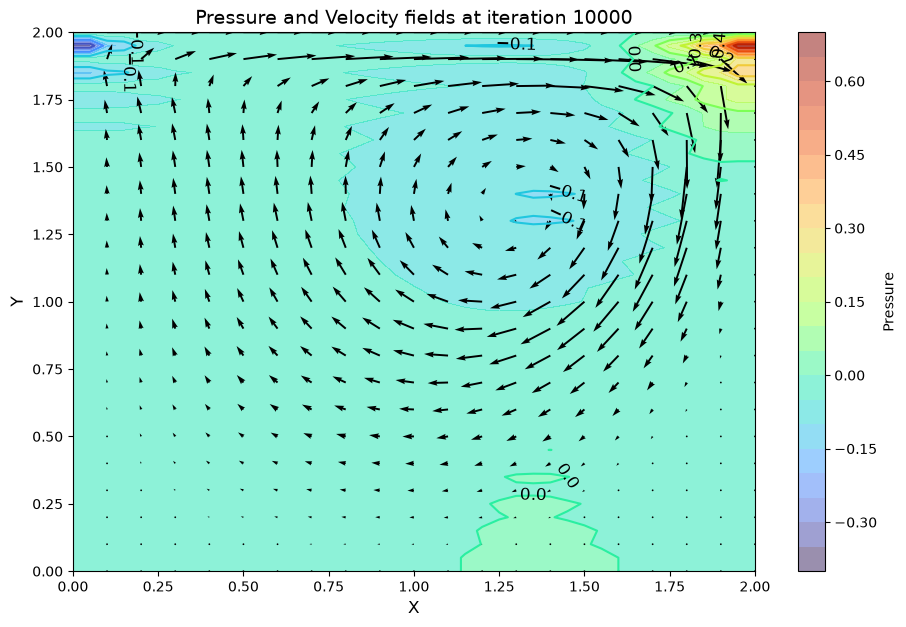

In [59]:
p = solution[-1][2]
u = solution[-1][0]
v = solution[-1][1]

# Create figure and set dpi and figure size
fig = plt.figure(figsize=(11,7), dpi=100)

# Contourf plot for pressure field with colorbar
cf = plt.contourf(X, Y, p, alpha=0.5, cmap='turbo', levels=20)
plt.colorbar(cf, label='Pressure')

# Contour plot for pressure field outlines
contour = plt.contour(X, Y, p, cmap='turbo', levels=10)
plt.clabel(contour, inline=False, fontsize=12, colors = 'black')

# Quiver plot for velocity field
quiv = plt.quiver(X[::2, ::2], Y[::2, ::2], u[::2, ::2], v[::2, ::2]) 

# Setting labels for the x and y axes
plt.xlabel('X', fontsize=12)
plt.ylabel('Y', fontsize=12)

# Setting the title for the plot
plt.title(f'Pressure and Velocity fields at iteration {nt}', fontsize=14)

# Display the plot
plt.show()

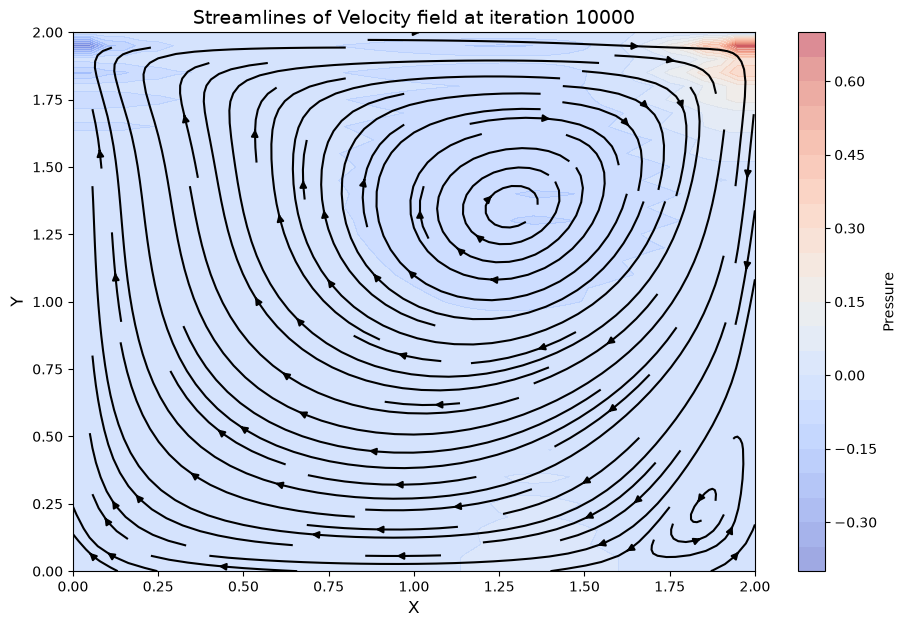

In [62]:
#streamplot for velocity field
plt.figure(figsize=(11,7), dpi=100)

# Contourf plot for pressure field with colorbar
cf = plt.contourf(X, Y, p, alpha=0.5, cmap='coolwarm', levels=20)
plt.colorbar(cf, label='Pressure')

plt.streamplot(X, Y, u, v, color='k', density=1.2)

plt.xlabel('X', fontsize=12)
plt.xlim(0, 2)

plt.ylabel('Y', fontsize=12)
plt.ylim(0, 2)
plt.title(f'Streamlines of Velocity field at iteration {nt}', fontsize=14)
plt.show()
